# Feature engineering — Constandino
Concert ticket purchase prediction (DSBA Kaggle challenge).

Part 2 of 2: builds new features from the cleaned data saved by `01_eda_constandino.ipynb` (run that notebook first).

## Imports and data

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from geopy.distance import geodesic

# load the cleaned data from 01_EDA
user_concert_train = pd.read_csv("../data/processed/train_clean.csv")
user_concert_test  = pd.read_csv("../data/processed/test_clean.csv")
print(user_concert_train.shape, user_concert_test.shape)

(30000, 34) (20000, 33)


## Numeric features

| Observations (pairplot + correlogram) | Creative idea/feature engineering |
|---|---|
| Booking fee = ticket price (perfect line) | Already dropped `booking_fee` |
| Spending band: higher band, more buying | Nothing to build. Already a number that goes up |
| Spending band vs typical spend: related (about 0.7) | Keep |
| Event page visits: more visits, more buying | Nothing to build. Already a count |
| Past purchase count vs first_timer (about -0.8): first-timers have 0 purchases | Keep both |
| Ticket price: distribution is trimodal, 3 modes | New feature `price_tier`: is this a cheap / normal or expensive ticket *for this concert*? ordinal: order matters, so 1,2,3 |
| Ticket price vs typical spend | New feature `price_vs_usual`: is this ticket pricier than what the person usually pays? |
| Usual booking lead days: flat on its own | New feature `lead_gap`: is the concert further away than they usually book? |
| Age: flat, no difference | Nothing to build. Keep it for now and let the model decide |
| Home/venue lat & lon: meaningless as raw numbers | New feature `distance_km_home_to_venue:` how far the person lives from the concert, then drop the 4 lat/lon columns |

In [3]:
user_concert_train.groupby("artist_name")["ticket_price"].describe()

,count,mean,std,min,25%,50%,75%,max
artist_name,,,,,,,,
Kendrick Lamar,6000.0,104.874000,15.703482,84.0,84.0,105.0,105.0,131.25
Olivia Rodrigo,6000.0,85.177792,12.859283,68.0,85.0,85.0,85.0,106.25
SZA,6000.0,95.013458,14.271883,76.0,76.0,95.0,95.0,118.75
Tame Impala,6000.0,75.038125,11.360866,60.0,60.0,75.0,75.0,93.75
Taylor Swift,6000.0,139.829667,20.921957,112.0,112.0,140.0,140.0,175.00


the mean ticket prices vary per concert

In [4]:
# check: each artist has exactly 3 different ticket prices
user_concert_train.groupby("artist_name")["ticket_price"].nunique()

artist_name
Kendrick Lamar    3
Olivia Rodrigo    3
SZA               3
Tame Impala       3
Taylor Swift      3
Name: ticket_price, dtype: int64

this is perfect for my feature engineering

In [5]:
#Feature engineering: numeric 

# 1. price_tier: 1 = cheapest, 2 = middle, 3 = most expensive ticket WITHIN each concert -- sos
# a ticket is only expensive relative to the concert ... 
user_concert_train["price_tier"] = user_concert_train.groupby("artist_name")["ticket_price"].rank(method="dense").astype(int)
user_concert_test["price_tier"]  = user_concert_test.groupby("artist_name")["ticket_price"].rank(method="dense").astype(int)
print(user_concert_train.groupby("price_tier")["buy"].mean())


price_tier
1    0.385718
2    0.330716
3    0.289312
Name: buy, dtype: float64


In [6]:
# first 10 rows, only the relevant columns
print(user_concert_train[["artist_name", "ticket_price", "price_tier"]].head(10))

      artist_name  ticket_price  price_tier
0     Tame Impala          75.0           2
1  Olivia Rodrigo          85.0           2
2    Taylor Swift         175.0           3
3  Kendrick Lamar          84.0           1
4             SZA          95.0           2
5  Kendrick Lamar         105.0           2
6     Tame Impala          75.0           2
7  Kendrick Lamar         105.0           2
8  Olivia Rodrigo          85.0           2
9    Taylor Swift         112.0           1


In [7]:
# 2. price_vs_usual: ticket price / what the person usually pays (above 1 = pricier than usual)
user_concert_train["price_vs_usual"] = user_concert_train["ticket_price"] / user_concert_train["typical_ticket_spend"]
user_concert_test["price_vs_usual"]  = user_concert_test["ticket_price"]  / user_concert_test["typical_ticket_spend"]


In [8]:
print(user_concert_train[["ticket_price", "typical_ticket_spend", "price_vs_usual"]].head(10))

   ticket_price  typical_ticket_spend  price_vs_usual
0          75.0              144.3300        0.519642
1          85.0              125.4625        0.677493
2         175.0               90.1200        1.941855
3          84.0              115.3200        0.728408
4          95.0              125.4625        0.757198
5         105.0              120.3550        0.872419
6          75.0              125.4625        0.597788
7         105.0              125.4625        0.836903
8          85.0              125.4625        0.677493
9         112.0               76.6500        1.461187


In [9]:
# 3. lead_gap: days until the concert minus how far ahead the person usually books
#    (positive = concert is further away than they usually book)
for df in [user_concert_train, user_concert_test]:
    df["days_to_concert"] = (pd.to_datetime(df["concert_at"]) - pd.to_datetime(df["prediction_at"])).dt.days
    df["lead_gap"] = df["days_to_concert"] - df["usual_booking_lead_days"]

In [10]:
print(user_concert_train[["concert_at", "prediction_at", "days_to_concert", "usual_booking_lead_days", "lead_gap"]].head(10))

             concert_at         prediction_at  days_to_concert  \
0  2026-12-12T20:00:00Z  2026-10-01T00:00:00Z               72   
1  2026-11-10T20:00:00Z  2026-10-01T00:00:00Z               40   
2  2026-11-26T20:00:00Z  2026-10-01T00:00:00Z               56   
3  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
4  2026-12-28T20:00:00Z  2026-10-01T00:00:00Z               88   
5  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
6  2026-12-12T20:00:00Z  2026-10-01T00:00:00Z               72   
7  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
8  2026-11-10T20:00:00Z  2026-10-01T00:00:00Z               40   
9  2026-11-26T20:00:00Z  2026-10-01T00:00:00Z               56   

   usual_booking_lead_days  lead_gap  
0                     31.0      41.0  
1                     50.0     -10.0  
2                     36.0      20.0  
3                     20.0       4.0  
4                     50.0      38.0  
5                     98.0     -74.0  


In [11]:
# acknowledgements: https://geopy.readthedocs.io/en/stable/

# distance_km: distance from the person's home to the concert venue, computed by geopy
for df in [user_concert_train, user_concert_test]:
    df["distance_km_home_to_venue"] = [geodesic((hlat, hlon), (vlat, vlon)).km
                         for hlat, hlon, vlat, vlon in zip(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])]

print(user_concert_train[["home_city","venue_city", "distance_km_home_to_venue"]].head(10))

  home_city venue_city  distance_km_home_to_venue
0    Nantes      Lille                 507.893880
1  Bordeaux       Lyon                 436.832882
2      Lyon   Bordeaux                 436.832882
3     Paris      Paris                   0.000000
4  Bordeaux     Nantes                 275.094820
5     Paris      Paris                   0.000000
6     Lille      Lille                   0.000000
7     Paris      Paris                   0.000000
8     Paris       Lyon                 391.733299
9     Paris   Bordeaux                 499.495089


### Check the new numeric features against buy

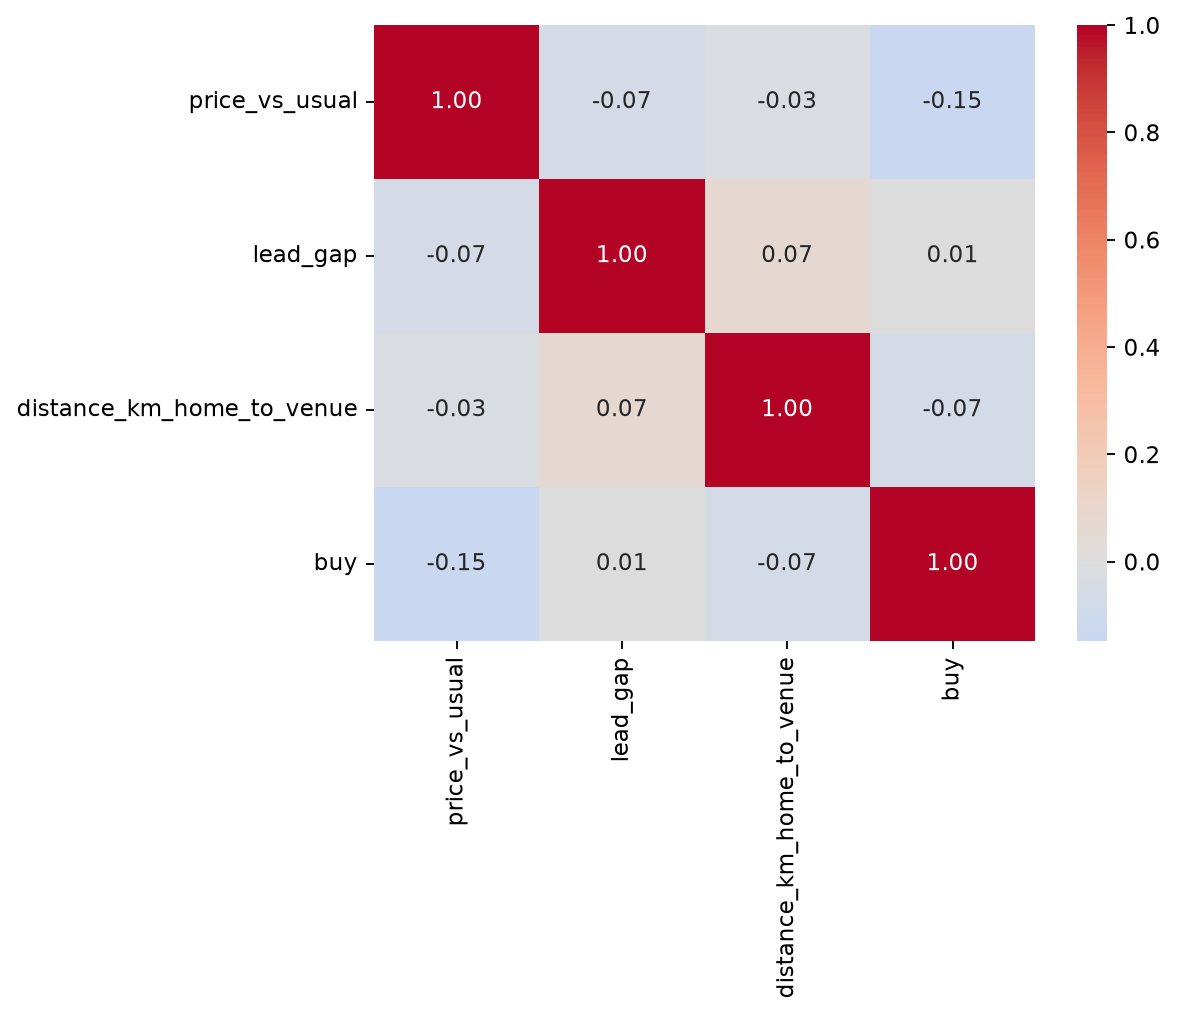

In [12]:
# use spearman because some distributions are skewed, checking the new numeric features against buy
sb.heatmap(user_concert_train[["price_vs_usual", "lead_gap", "distance_km_home_to_venue", "buy"]].corr(method="spearman"),
           cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.show()

1) price_tier ---> buy rate drops from 38.6% (cheapest) to 33.1% to 28.9% (most expensive ticket of the concert)
2) price_vs_usual ---> -0.15 with buy: people buy less when the ticket costs more than they usually pay (2nd strongest numeric signal after typical_ticket_spend at 0.22)
3) distance_km_home_to_venue ---> -0.07: people further away buy a little less, weak because same_city already captures most of it
4) lead_gap ---> 0.01: no link to buying, so drop it

In [13]:
# lead_gap: no link to buy (0.01), drop it with its helper column days_to_concert
user_concert_train = user_concert_train.drop(columns=["lead_gap", "days_to_concert"])
user_concert_test  = user_concert_test.drop(columns=["lead_gap", "days_to_concert"])

## Categorical features

| from a,b,c,d,e | Creative idea/feature engineering |
|---|---|
| Home city: weak on its own | New feature `same_city`: does the person live in the concert's city? |
| Education: no difference | Nothing to build. Keep it for now and let the model decide |
| Favourite genre: pop highest, metal lowest | New feature `genre_match`: is their genre one of the concert's genres? |
| Artist: Taylor Swift highest, Tame Impala lowest | Nothing to build. `artist_name` is already the feature |
| Venue city = artist | Use it to build the features below, then drop it |
| Travel search: concert city about 40%, other cities about 30% | New feature `travel_to_venue`: did they search for travel to this concert's city? |
| Discount: rises with discount | Nothing to build. It's already a number that goes up |
| Wishlisted: 43% vs 32% | Nothing to build. Already a 0/1 flag |
| First timers: 37% vs 32% | Nothing to build. Already a 0/1 flag |

In [14]:
#Feature engineering: categorical 
for df in [user_concert_train, user_concert_test]:
    #1. create same_city,,, 1 if the person lives in the concert's city
    df["same_city"] = (df["home_city"] == df["venue_city"]).astype(int)

    #3. create genre_match,,, if looping through the genres finds a match then assign 1
    df["genre_match"] = [int(g in gs.split("|")) for g, gs in zip(df["stated_favourite_genre"], df["genres"])]

    #6. travel_to_venue: 1 if they searched travel to THIS concert's city
    df["travel_to_venue"] = (df["travel_search_city"] == df["venue_city"]).astype(int)

# checks (train only, since test has no buy column)
print(user_concert_train.groupby("same_city")["buy"].mean())
print(user_concert_train.groupby("genre_match")["buy"].mean())
print(user_concert_train.groupby("travel_to_venue")["buy"].mean())

same_city
0    0.322878
1    0.411791
Name: buy, dtype: float64
genre_match
0    0.295247
1    0.424776
Name: buy, dtype: float64
travel_to_venue
0    0.317622
1    0.453724
Name: buy, dtype: float64


1) same_city ---> people buy more when the concert is in their own city (41% vs 32%) probably because it’s easier to get to.
2) genre_match --> people buy more when the concert matches their favourite genre (42% vs 30%) aka they like the music.
3) travel_to_venue ---> people who searched for travel to the concert’s city buy the most (45% vs 32%) maybe because they’re already planning to go,(its like a lead)

In [15]:
# 7. Discount: rises with discount -> nothing to build
# 8. Wishlisted: 43% vs 32% -> nothing to build
# 9. First timers: 37% vs 32% -> nothing to build

# dropping what i mentioned
user_concert_train = user_concert_train.drop(columns=["venue_city", "genres", "home_lat", "home_lon", "venue_lat", "venue_lon"])
user_concert_test  = user_concert_test.drop(columns=["venue_city", "genres", "home_lat", "home_lon", "venue_lat", "venue_lon"])

## Music app features (music_app.json)

In [16]:
import json

# ---------- Music app features ----------

# 1. load the JSON and flatten it into one row per song played
with open("../data/raw/music_app.json") as f:
    music = json.load(f)

rows = []
for account in music["accounts"]:                 # each person
    for session in account["sessions"]:           # each listening session
        for track in session["tracks"]:           # each song played
            rows.append({"music_app_user_id": account["music_app_user_id"],
                         "artist_id": track["artist_id"],
                         "minutes": track["played_ms"] / 60000,
                         "saved": int(track["saved"])})
plays = pd.DataFrame(rows)
del music, rows   # free the memory, the big JSON object isn't needed any more

# 2. summarise: per person + artist, and per person in total
artist_listening = plays.groupby(["music_app_user_id", "artist_id"]).agg(
    artist_minutes=("minutes", "sum"),      # minutes this person listened to this artist
    artist_saves=("saved", "sum")           # songs by this artist they saved
).reset_index()
total_listening = plays.groupby("music_app_user_id")["minutes"].sum().rename("total_minutes").reset_index()

# 3. join onto train and test
def add_listening(df):
    df = df.merge(artist_listening, on=["music_app_user_id", "artist_id"], how="left")
    df = df.merge(total_listening, on="music_app_user_id", how="left")
    df[["artist_minutes", "artist_saves", "total_minutes"]] = df[["artist_minutes", "artist_saves", "total_minutes"]].fillna(0)
    df["artist_share"] = (df["artist_minutes"] / df["total_minutes"]).fillna(0)   # share of their listening that goes to this artist
    return df

user_concert_train = add_listening(user_concert_train)
user_concert_test  = add_listening(user_concert_test)

print(user_concert_train[["artist_name", "artist_minutes", "artist_saves", "total_minutes", "artist_share"]].head(10))

      artist_name  artist_minutes  artist_saves  total_minutes  artist_share
0     Tame Impala        0.000000           0.0     179.640233      0.000000
1  Olivia Rodrigo       24.449433           4.0     142.060583      0.172106
2    Taylor Swift        0.632617           0.0     118.825083      0.005324
3  Kendrick Lamar        1.035650           0.0     216.812917      0.004777
4             SZA        9.209683           1.0     119.718500      0.076928
5  Kendrick Lamar        0.000000           0.0       0.000000      0.000000
6     Tame Impala       15.693383           2.0     158.820983      0.098812
7  Kendrick Lamar        0.000000           0.0      97.752217      0.000000
8  Olivia Rodrigo        0.000000           0.0       0.000000      0.000000
9    Taylor Swift       32.811600           5.0     119.809600      0.273865


### Check the music app features against buy

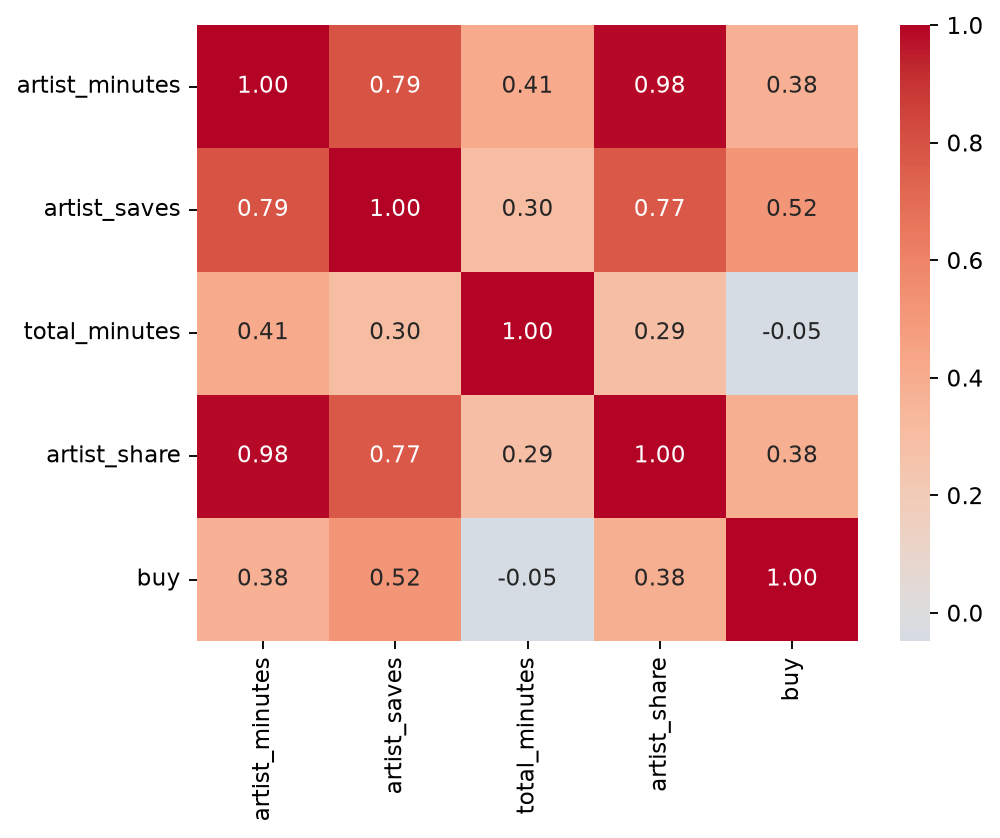

In [17]:
sb.heatmap(user_concert_train[["artist_minutes", "artist_saves", "total_minutes", "artist_share", "buy"]].corr(method="spearman"),
           cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.show()

Observations: (fill in after running)

## Final column drop
Columns that have done their job: IDs used only for joining, concert columns that are one-to-one with `artist_name`, single-value dates, and the raw travel columns replaced by `searched_travel` / `travel_to_venue`.
`row_id` and `user_id` are kept for the submission file and the user-based validation split, but are never used as model inputs.

In [18]:
cols_to_drop = ["music_app_user_id", "artist_id",                   # only needed to join the music app data
                "concert_id", "concert_at",                          # one-to-one with artist_name
                "sale_opened_at", "prediction_at",                   # single value
                "travel_search_city", "travel_search_arrival"]       # replaced by searched_travel / travel_to_venue
user_concert_train = user_concert_train.drop(columns=cols_to_drop)
user_concert_test  = user_concert_test.drop(columns=cols_to_drop)

#moves buy to the end
user_concert_train["buy"] = user_concert_train.pop("buy")

print(user_concert_train.columns.to_list())

['row_id', 'user_id', 'age', 'education', 'spending_capacity_band', 'home_city', 'stated_favourite_genre', 'past_purchase_count', 'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'artist_name', 'ticket_price', 'discount_pct', 'event_page_visits_7d', 'wishlisted', 'has_music_app', 'visits_missing', 'searched_travel', 'price_tier', 'price_vs_usual', 'distance_km_home_to_venue', 'same_city', 'genre_match', 'travel_to_venue', 'artist_minutes', 'artist_saves', 'total_minutes', 'artist_share', 'buy']


## Final check and save

In [19]:
# same columns in train and test (apart from buy), no missing values
print(set(user_concert_train.columns) - set(user_concert_test.columns))
print(user_concert_train.isnull().sum().sum(), user_concert_test.isnull().sum().sum())

user_concert_train.to_csv("../data/processed/train_features_constandino.csv", index=False)
user_concert_test.to_csv("../data/processed/test_features_constandino.csv", index=False)
print(user_concert_train.shape, user_concert_test.shape)

{'buy'}
0 0
(30000, 30) (20000, 29)
